In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded
from scipy.integrate import solve_ivp


observaciones:

1. Alejar la frontera esta muy cerca limitar r=10. (nose porque genera problemas si acerco la frontera)
2. Implementar tu propio solver Thomas en NumPy.
3. Crear mi propio rugge kutta4.

In [ ]:
# ------------------------------------ Construcción de la malla -----------------------------------------------------------------
M = 1.0                        # Masa
rmin = 0.0
rmax = 25.0
N = 2000                                         # Número de puntos físicos en la malla
delta_r = (rmax - rmin) / N
points_r_interior = np.linspace(rmin + 0.5*delta_r, rmax - 0.5*delta_r, N)                # Creo el intervalo de puntos fisicos de mi sistema


# Condiciones iniciales --------------------------------------------------
alpha   = np.ones(N)
Atilde  = np.ones(N)
Btilde  = np.ones(N)
KA      = np.zeros(N)
KB      = np.zeros(N)
DAtilde = np.zeros(N)
DBtilde = np.zeros(N)

# Factor conforme para Schwarzschild en coordenadas isotrópicas
psi = 1.0 + M / (2.0 * points_r_interior)
# Derivada analítica de ln(psi)
lnpsi = np.log(psi)
dr_lnpsi = -M / (points_r_interior * (2.0 * points_r_interior + M))
ddlnpsi_estatico = (M * (4.0 * points_r_interior + M)/ (points_r_interior**2 * (2.0 * points_r_interior + M)**2 ))

def agregar_fantasmas(f_fisico, paridad, dr, BCrmax, r_max, ghost_points=2, f_inf=0.0):
    """
    Extiende f_fisico con 'ghost_points' fantasmas en cada extremo de forma vectorizada.
    En r=0 aplica simetría de paridad (+1 par, -1 impar).
    En r=rmax aplica decaimiento asintótico: f(r) - f_inf ~ (1/r)^BCrmax.
    """
    N_fisico = len(f_fisico)
    f_full = np.empty(N_fisico + 2 * ghost_points)
    f_full[ghost_points:-ghost_points] = f_fisico

    # Frontera interior (invierte los primeros 'ghost_points' elementos físicos)
    f_full[:ghost_points] = paridad * f_fisico[ghost_points - 1 :: -1]

    # Frontera exterior vectorizada para cualquier ghost_points y exponente BCrmax
    k = np.arange(1, ghost_points + 1)
    factor_decaimiento = (r_max / (r_max + k * dr)) ** BCrmax
    f_full[-ghost_points:] = f_inf + (f_fisico[-1] - f_inf) * factor_decaimiento

    return f_full


def D1_4_order(f_fisico, dr, BCrmax, paridad=1, r_max=points_r_interior[-1], f_inf=0.0):
    """Primera derivada centrada de 4to orden."""
    f = agregar_fantasmas(f_fisico, paridad, dr, BCrmax, r_max, ghost_points=2, f_inf=f_inf)
    return (-f[4:] + 8.0 * f[3:-1] - 8.0 * f[1:-3] + f[:-4]) / (12.0 * dr)


def disipacion_KO_6(f_fisico, paridad, dr, BCrmax, eps_KO=0.01, r_max=points_r_interior[-1], f_inf=0.0):
    """
    Disipación de Kreiss-Oliger de 6to orden.
    NOTA: Debe SUMARSE (+ D_KO) en el RHS de las ecuaciones de evolución.
    """
    f = agregar_fantasmas(f_fisico, paridad, dr, BCrmax, r_max, ghost_points=3, f_inf=f_inf)
    return (eps_KO / (64.0 * dr)) * (
        f[:-6]
        - 6.0 * f[1:-5]
        + 15.0 * f[2:-4]
        - 20.0 * f[3:-3]
        + 15.0 * f[4:-2]
        - 6.0 * f[5:-1]
        + f[6:]
    )


In [ ]:
def resolver_bvp_alpha_4to_orden_estricto(Atilde, DBtilde, DAtilde, KA, KB, psi, dlnpsi1, r, dr):
    """ Calcula el nuevo valor de alpha sujeto a simetría par en la frontera interior
    y decaimiento (1 - alpha)/r en la exterior, reemplazando el resultado en las
    ecuaciones de evolución para la siguiente iteración.
    """
    N = len(r)

    # Coeficientes P(r) y Q_tilde(r)
    P = DBtilde - 0.5 * DAtilde + 4/(2*r+M)
    Q_tilde = Atilde * (psi**4) * (KA**2 + 2.0 * (KB**2))

    # 1. Vectores para las 5 diagonales interiores (multiplicado por 12*dr^2)
    ll = -1.0 + P * dr                 # Diagonal inferior -2
    l  = 16.0 - 8.0 * P * dr           # Diagonal inferior -1
    m  = -30.0 - 12.0 * Q_tilde * (dr**2)  # Diagonal principal
    u  = 16.0 + 8.0 * P * dr           # Diagonal superior +1
    uu = -1.0 - P * dr                 # Diagonal superior +2

    b = np.zeros(N)


    # CONSTRUCCIÓN DE LA MATRIZ  (formato para solve_banded)
    # L(inferiores) = 4, U(superiores) = 2. Dimensión de ab = (4 + 2 + 1, N) = (7, N)
    # La regla de mapeo es: ab[U + i - j, j] = Matriz_Original[i, j]
    ab = np.zeros((7, N))

    # Llenado de las diagonales estándar
    ab[0, 2:] = uu[:-2]   # Diagonal superior +2 (fila 0 de ab)
    ab[1, 1:] = u[:-1]    # Diagonal superior +1 (fila 1 de ab)
    ab[2, :]  = m         # Diagonal principal   (fila 2 de ab)
    ab[3, :-1] = l[1:]    # Diagonal inferior -1 (fila 3 de ab)
    ab[4, :-2] = ll[2:]   # Diagonal inferior -2 (fila 4 de ab)

    # Frontera interior
    # Fila 0 (i=0): f[-1] -> f[1] y f[-2] -> f[2]
    # Matriz_Original[0, 0] += l[0]  --> ab[2 + 0 - 0, 0]
    ab[2, 0] += l[0]
    # Matriz_Original[0, 1] += ll[0] --> ab[2 + 0 - 1, 1]
    ab[1, 1] += ll[0]

    # Fila 1 (i=1): f[-1] -> f[1] (Cae sobre la diagonal principal)
    # Matriz_Original[1, 0] += ll[1] --> ab[2 + 1 - 0, 0]
    ab[3, 0] += ll[1]

    # FRONTERA EXTERIOR
    # --- Fila N-2 (Penúltimo punto) ---
    j_idx = N - 2
    ab[1, j_idx+1] = 11.0 + 3.0 * P[j_idx] * dr
    ab[2, j_idx]   = -20.0 + 10.0 * P[j_idx] * dr - 12.0 * Q_tilde[j_idx] * (dr**2)
    ab[3, j_idx-1] = 6.0 - 18.0 * P[j_idx] * dr
    ab[4, j_idx-2] = 4.0 + 6.0 * P[j_idx] * dr
    ab[5, j_idx-3] = -1.0 - P[j_idx] * dr      # Diagonal inferior -3 (fila 5 de ab)

    # --- Fila N-1 (Último punto del dominio) ---
    k = N - 1
    r_bound = r[k]

    ab[2, k]   = 25.0 + 12.0 * dr / r_bound    # Principal
    ab[3, k-1] = -48.0                         # Inferior -1
    ab[4, k-2] = 36.0                          # Inferior -2
    ab[5, k-3] = -16.0                         # Inferior -3
    ab[6, k-4] = 3.0                           # Inferior -4 (fila 6 de ab)

    # El lado derecho de la ecuación de Robin
    b[k] = 12.0 * dr / r_bound

    # Resolvemos directamente el sistema (4 diagonales abajo, 2 diagonales arriba)
    return solve_banded((4, 2), ab, b)

In [ ]:
def RHS(t, y_global, N, r, dr=delta_r):
    # Desempaquetamiento
    A_tilde  = y_global[0:N]
    B_tilde  = y_global[N:2*N]
    DA_tilde = y_global[2*N:3*N]
    DB_tilde = y_global[3*N:4*N]
    KA       = y_global[4*N:5*N]
    KB       = y_global[5*N:6*N]

    # 2. Ecuación elíptica para el Lapse
    alpha = resolver_bvp_alpha_4to_orden_estricto(
        A_tilde, DB_tilde, DA_tilde,
        KA, KB, psi, dr_lnpsi, r, dr
    )


    # 3. Derivadas espaciales (Diferencias Finitas)
    lnalpha = np.log(alpha)
    Dalpha  = D1_4_order(lnalpha, dr, 1,paridad=1)
    dKA     = D1_4_order(KA, dr, 3,paridad=1)
    dKB     = D1_4_order(KB, dr,3, paridad=1)

    dDB     = D1_4_order(DB_tilde, dr,3, paridad=-1)
    dDalpha = D1_4_order(Dalpha, dr, 1,paridad=-1)

    # 4. Evolución de las variables
    dA_dt = -2 * alpha * A_tilde * KA
    dB_dt = -2 * alpha * B_tilde * KB

    dDA_dt = -2 * alpha * (KA * Dalpha + dKA)
    dDB_dt = -2 * alpha * (KB * Dalpha + dKB)

    T2 = Dalpha**2
    T3 = -0.5 * Dalpha * (DA_tilde + 4 * dr_lnpsi)
    T1 = dDalpha + dDB -(1/r) * (DA_tilde  - 2 * DB_tilde) + 8*M/(r*(2*r+M)**2)
    T4 = (1/2)*(DB_tilde + 4 * dr_lnpsi)*(DB_tilde -DA_tilde)

    dKA_dt = -alpha / (psi**4 * A_tilde) * (T1 + T2 + T3 + T4  )  +    alpha * KA * (KA + 2 * KB)

    S1 = dDB + 4 * ddlnpsi_estatico
    S2 = Dalpha * (DB_tilde + 4 * dr_lnpsi)
    S3= (DB_tilde + 4 * dr_lnpsi)*(DB_tilde -1/2 * DA_tilde + 2*dr_lnpsi)
    S5 = -1/r * (DA_tilde -2*Dalpha -4*DB_tilde - 12*dr_lnpsi)
    S6 =  -2.0 * (A_tilde - B_tilde) / (B_tilde * (r**2))

    dKB_dt = (-alpha / (2 * psi**4 * A_tilde) * (S1 + S2 + S3  +S5+S6) + alpha * KB * (KA + 2 * KB))



    dA_dt  += disipacion_KO_6(A_tilde,  paridad=1,  dr=dr,BCrmax=1 ,f_inf=1)
    dB_dt  += disipacion_KO_6(B_tilde,  paridad=1,  dr=dr,BCrmax=1 ,f_inf=1)
    dKA_dt += disipacion_KO_6(KA,       paridad=1,  dr=dr,BCrmax=3 )
    dKB_dt += disipacion_KO_6(KB,       paridad=1,  dr=dr,BCrmax=3 )
    dDA_dt += disipacion_KO_6(DA_tilde, paridad=-1, dr=dr,BCrmax=3 )
    dDB_dt += disipacion_KO_6(DB_tilde, paridad=-1, dr=dr,BCrmax=3 )


    return np.concatenate([dA_dt, dB_dt, dDA_dt, dDB_dt, dKA_dt, dKB_dt])

In [ ]:
delta_t=delta_r*0.5
ti=0
tf=15
t_span=(ti,tf)
y0=np.concatenate([Atilde,Btilde,DAtilde,DBtilde,KA,KB])  # Se concatenan las condiciones iniciales
t_eval=np.arange(ti,tf,delta_t)

# Se da inicio a la evolucion del sistema
sol = solve_ivp(
    RHS,
    t_span,
    y0,
    t_eval=t_eval,
    args=(N, points_r_interior),
    method="RK45",
    max_step=delta_t
)


Aqui se graficaran las ecuaciones de ligadura, ya que nos ayudara a saber como evoluciona el sistema y que tan fisico se comporta la evolucion.

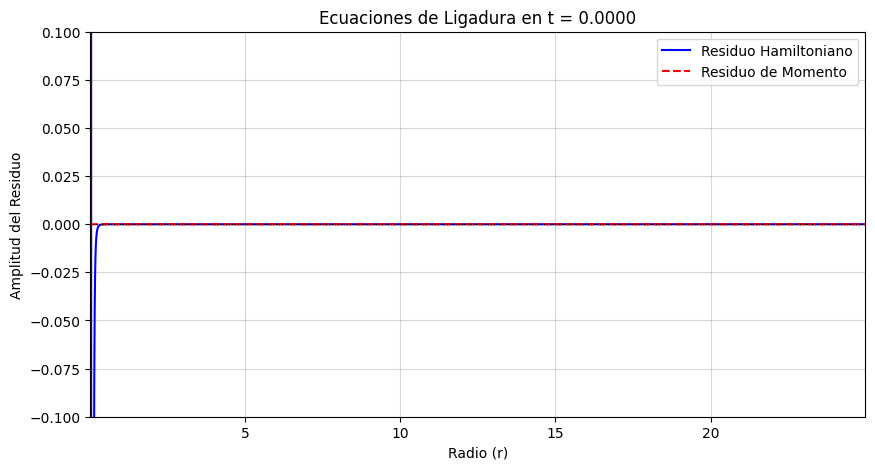

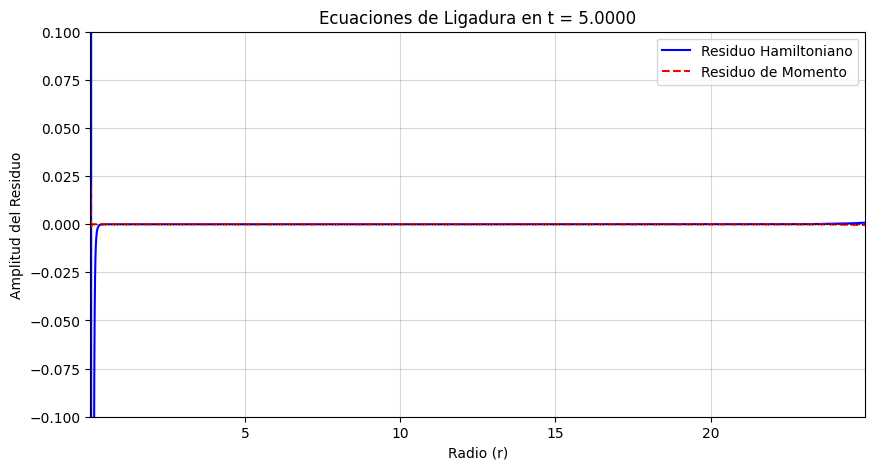

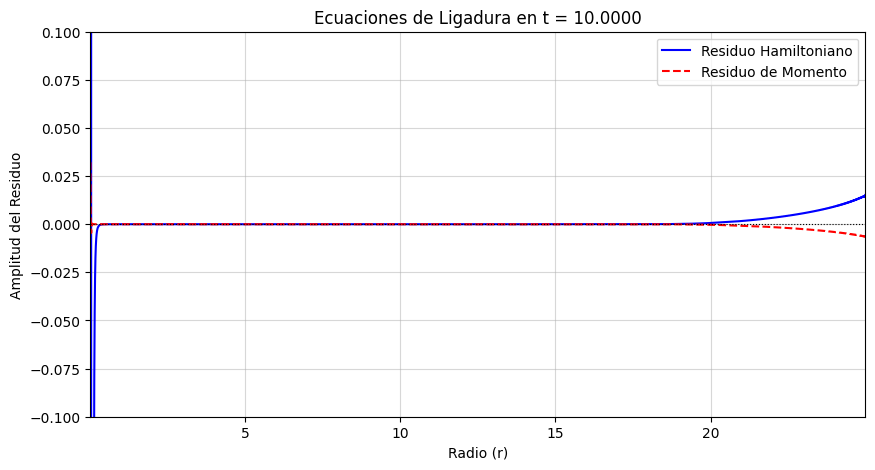

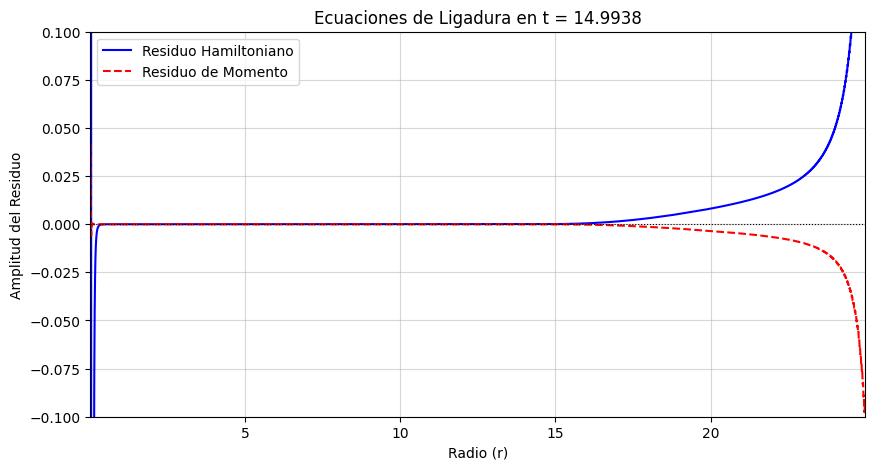

In [ ]:
# 1. Definir los 4 índices de tiempo que queremos graficar
n_tiempos = len(sol.t)
indices_a_graficar = [
    0,                      # Primer tiempo
    n_tiempos // 3,         # Segundo tiempo
    2 * n_tiempos // 3,     # Tercer tiempo
    -1                      # Último tiempo
]

r = points_r_interior


for indice_t in indices_a_graficar:
    tiempo_actual = sol.t[indice_t]
    # Extraccion de las solucion para un tiempo t
    y_t = sol.y[:, indice_t]

    # Desempaquetar las variables conformes
    A_tilde  = y_t[0:N]
    B_tilde  = y_t[N:2*N]
    DA_tilde = y_t[2*N:3*N]
    DB_tilde = y_t[3*N:4*N]
    KA       = y_t[4*N:5*N]
    KB       = y_t[5*N:6*N]

    # Transformar a variables físicas
    A = A_tilde * psi**4
    B = B_tilde * psi**4
    DA = DA_tilde + 4 * dr_lnpsi
    DB = DB_tilde + 4 * dr_lnpsi

    dr_DB = D1_4_order(DB, delta_r, 1,paridad=-1)
    dr_KB = D1_4_order(KB, delta_r,1, paridad=1)

    # Ligadura Hamiltoniana
    term1_H =  (A_tilde - B_tilde) / (B_tilde * (r**2))
    term2_H = A * KB * (2.0 * KA + KB)
    term3_H = (1.0 / r) * (DA - 3.0 * DB)
    term4_H = (DA * DB) / 2.0
    term5_H = (3.0 * DB**2) / 4.0

    H_diference = dr_DB - (term1_H + term2_H + term3_H + term4_H - term5_H)

    # Ligadura de Momento (M)
    M_diference = dr_KB - (KA - KB) * ((1.0 / r) + (DB / 2.0))


    # 7. Graficar los resultados
    plt.figure(figsize=(10, 5))
    plt.plot(r, H_diference, label=f"Residuo Hamiltoniano", color="blue")
    plt.plot(r, M_diference, label=f"Residuo de Momento", color="red", linestyle="--")
    plt.xlim(r[0], r[-1])
    plt.ylim(-0.1, 0.1)

    # Formatear el título para que muestre el valor de t con 4 decimales
    plt.title(f"Ecuaciones de Ligadura en t = {tiempo_actual:.4f}")
    plt.xlabel("Radio (r)")
    plt.ylabel("Amplitud del Residuo")
    plt.axhline(0, color='black', linewidth=0.8, linestyle=":")
    plt.legend()
    plt.grid(True, alpha=0.5)
    plt.show()

La gráfica permite apreciar cómo las inestabilidades numéricas generan errores que a medida que el sistema evoluciona, conducen al incumplimiento de las ecuaciones de ligadura y a la pérdida de consistencia física. Esta incertidumbre se incrementa exponencialmente en la frontera exterior, lo que plantea la necesidad de examinar la causa subyacente de esta divergencia

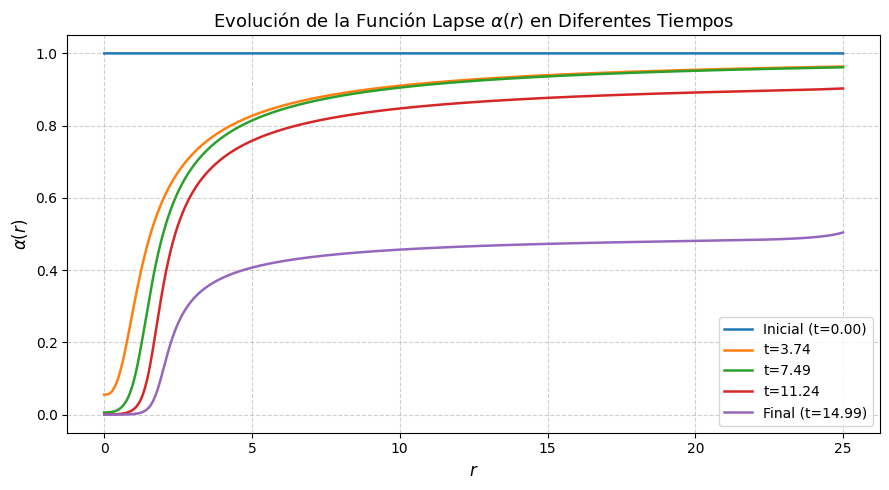

In [ ]:
lapsefunction_correcto = []
n_tiempos = len(sol.t)

for i in range(n_tiempos):
    # Extraer el estado del sistema en el tiempo exacto sol.t[i]
    y_i = sol.y[:, i]

    A_tilde_i  = y_i[0:N]
    B_tilde_i  = y_i[N:2*N]
    DA_tilde_i = y_i[2*N:3*N]
    DB_tilde_i = y_i[3*N:4*N]
    KA_i       = y_i[4*N:5*N]
    KB_i       = y_i[5*N:6*N]

    # Calcular alpha solo para los pasos de tiempo reales y aceptados
    alpha_i = resolver_bvp_alpha_4to_orden_estricto(
        A_tilde_i, DB_tilde_i, DA_tilde_i,
        KA_i, KB_i, psi, dr_lnpsi, points_r_interior, delta_r
    )
    lapsefunction_correcto.append(alpha_i)

indices = np.linspace(0, n_tiempos - 1, 5, dtype=int)

plt.figure(figsize=(9, 5), dpi=100)

for idx in indices:
    t_actual = sol.t[idx]
    if idx == 0:
        etiqueta = f"Inicial (t={t_actual:.2f})"
    elif idx == indices[-1]:
        etiqueta = f"Final (t={t_actual:.2f})"
    else:
        etiqueta = f"t={t_actual:.2f}"

    plt.plot(points_r_interior, lapsefunction_correcto[idx], label=etiqueta, linewidth=1.8)

plt.xlabel("$r$", fontsize=12)
plt.ylabel(r"$\alpha(r)$", fontsize=12)
plt.title(r"Evolución de la Función Lapse $\alpha(r)$ en Diferentes Tiempos", fontsize=13)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="best", frameon=True)
plt.tight_layout()
plt.show()

Ahora por nuestro gauge escogido la funcion lapse deberia caer a cero en la singularidad, cosa que si observamos la grafica ocurre.

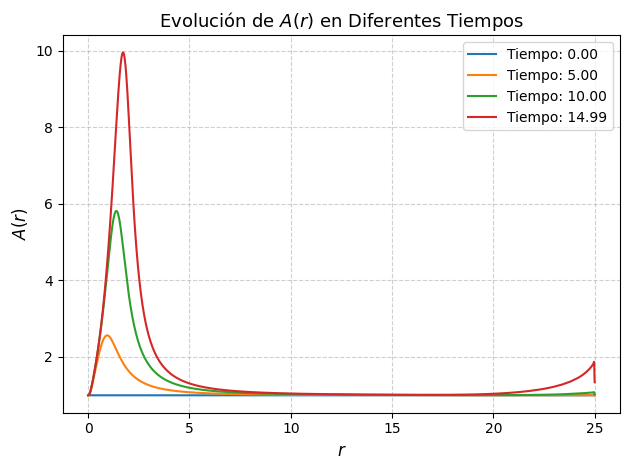

In [ ]:
for i in indices_a_graficar:
  y_i = sol.y[:, i]
  A_tilde123= y_i[0:N]

  plt.plot(points_r_interior, A_tilde123, label=f"Tiempo: {sol.t[i]:.2f}")

plt.xlabel("$r$", fontsize=12)
plt.ylabel(r"$A(r)$", fontsize=12)
plt.title(r"Evolución de $A(r)$ en Diferentes Tiempos", fontsize=13)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="best", frameon=True)
plt.tight_layout()
plt.show()

La gráfica ilustra  de A(r), no da un comportamiento que se puede asociar a las ecuaciones de ligadura. Teóricamente, el perfil físico debería exhibir un máximo local en el horizonte de eventos y luego decrecer de forma monótona hacia 1 para valores grandes de $r$. No obstante, en la frontera exterior el valor de $A$ se amplifica de forma drástica a medida que avanza la evolución, fenómeno consistente con la divergencia de las ecuaciones de ligadura y la consecuente pérdida de validez física en los límites del dominio.

In [ ]:
def calcular_expansion_theta(
    A_tilde, B_tilde, DB_tilde, KB, psi, dr_lnpsi, r, K_traza=0.0
):
    """Calcula el perfil espacial de la expansión Theta(r) usando DB_tilde directo."""
    # Uso de la identidad analítica d(ln(B))/dr = dB_dr / B

    parte_espacial = (1.0 / (psi**2 * np.sqrt(A_tilde))) * (
        (2.0 / r) + DB_tilde + 4.0 * dr_lnpsi
    )
    parte_temporal = -2.0 * (KB + (1.0 / 3.0) * K_traza)

    return parte_espacial + parte_temporal



In [ ]:
def encontrar_horizonte_aparente(theta_r, r, r_esperado):
    """Encuentra la raíz r donde Theta(r) = 0 más cercana a la posición física."""
    cambios_signo = np.where(np.diff(np.sign(theta_r)))[0]

    if len(cambios_signo) == 0:
        return None

    raices = []
    for idx in cambios_signo:
        r1, r2 = r[idx], r[idx+1]
        t1, t2 = theta_r[idx], theta_r[idx+1]

        # Evitar división por cero
        if t1 == t2:
            continue

        r_exacto = r1 - t1 * (r2 - r1) / (t2 - t1)
        raices.append(r_exacto)

    # Seleccionar la raíz más cercana al valor teórico esperado
    r_ah_correcto = min(raices, key=lambda rc: abs(rc - r_esperado))
    return r_ah_correcto

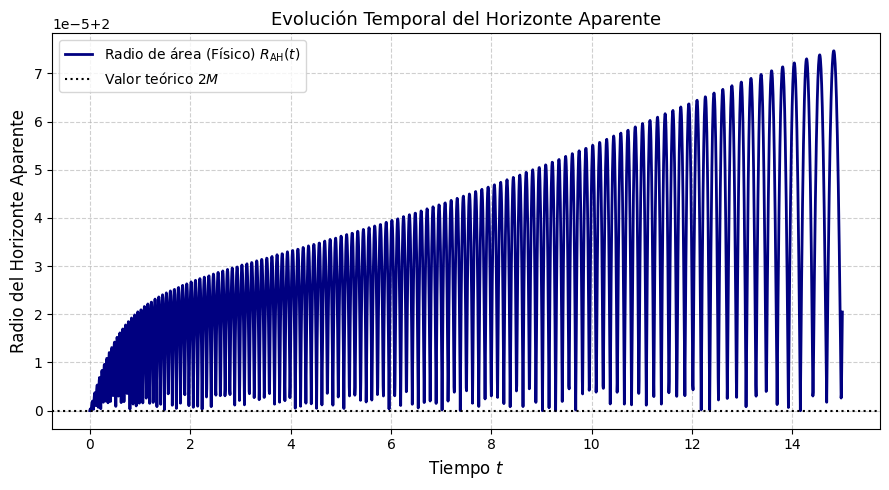

In [ ]:
tiempos = []
r_AH_list = []
R_AH_list = []

n_tiempos = len(sol.t)
r_esperado = 0.5 * M  # Estimación inicial para el horizonte

for idx in range(n_tiempos):
    t_val = sol.t[idx]
    y_t = sol.y[:, idx]

    A_tilde_t = y_t[0:N]
    B_tilde_t = y_t[N : 2 * N]
    DB_tilde_t = y_t[3 * N : 4 * N]
    KB_t = y_t[5 * N : 6 * N]

    theta_r = calcular_expansion_theta(
        A_tilde_t, B_tilde_t, DB_tilde_t, KB_t, psi, dr_lnpsi, points_r_interior
    )

    r_ah = encontrar_horizonte_aparente(theta_r, points_r_interior, r_esperado)

    if r_ah is not None:
        tiempos.append(t_val)
        r_AH_list.append(r_ah)

        B_ah = np.interp(r_ah, points_r_interior, B_tilde_t)
        psi_ah = 1.0 + M / (2.0 * r_ah)

        R_ah = r_ah * (psi_ah**2) * np.sqrt(B_ah)
        R_AH_list.append(R_ah)

        # Actualizamos la estimación para que siga al horizonte dinámicamente
        r_esperado = r_ah

plt.figure(figsize=(9, 5), dpi=100)

if len(r_AH_list) > 0:
    # plt.plot(
    #     tiempos,
    #     r_AH_list,
    #     label=r"Radio de coordenadas $r_{\mathrm{AH}}(t)$",
    #     color="crimson",
    #     linewidth=2,
    #     linestyle="--"
    # )
    plt.plot(
        tiempos,
        R_AH_list,
        label=r"Radio de área (Físico) $R_{\mathrm{AH}}(t)$",
        color="navy",
        linewidth=2,
    )

    plt.axhline(2.0 * M, color="black", linestyle=":", label="Valor teórico $2M$")

    plt.xlabel("Tiempo $t$", fontsize=12)
    plt.ylabel("Radio del Horizonte Aparente", fontsize=12)
    plt.title("Evolución Temporal del Horizonte Aparente", fontsize=13)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(loc="best", frameon=True)
    plt.tight_layout()
    plt.show()
else:
    print("No se encontró horizonte aparente en ningún instante de tiempo.")

Como estamos tomando M=1, el radio de coordenas de el agujero negro es 2, y este a su vez es invariante bajo la eleccion de las coordenadas, ahora bien observamos como dicho valor esta bastante cercanio a dos oscila sobre este valor sin nuca tomar valores menores que este, tambien notamos como al aumentar el paso del tiempo la amplitud de dicha evolucion crece

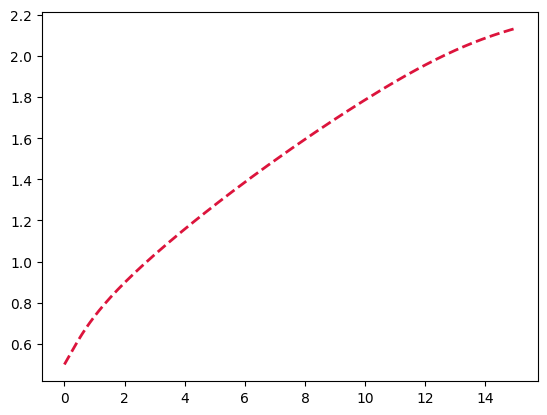

In [ ]:
plt.plot(
        tiempos,
        r_AH_list,
        label=r"Radio de coordenadas $r_{\mathrm{AH}}(t)$",
        color="crimson",
        linewidth=2,
        linestyle="--"
    )

Observamos un crecimiento lineal de el horizonte de eventos cosa esperada por nuestros gauges escogidos, recordad que dicho cambio no es fisico.

In [ ]:
# Asumiendo que ya calculaste A, B, DB y KB como en el script anterior
r = points_r_interior

# Calcular la expansión nula saliente (Theta)
Theta = (1.0 / np.sqrt(A)) * (DB + 2.0 / r) - 2.0 * KB

# Encontrar el radio del horizonte aparente (interpolando donde Theta cruza 0)
# Theta suele ser negativo dentro del agujero negro y positivo afuera
sign_changes = np.where(np.diff(np.sign(Theta)))[0]

if len(sign_changes) > 0:
    # Tomamos el cruce más externo si hubiera múltiples (por definición del horizonte aparente)
    idx = sign_changes[-1]

    # Interpolación lineal básica para mayor precisión entre los puntos de la malla
    r1, r2 = r[idx], r[idx+1]
    t1, t2 = Theta[idx], Theta[idx+1]

    r_horizonte = r1 - t1 * ((r2 - r1) / (t2 - t1))
    print(f"Horizonte aparente encontrado en r = {r_horizonte:.4f}")
else:
    print("No se encontró horizonte aparente en la malla actual.")

Horizonte aparente encontrado en r = 2.1322
